# EEG Decoding Workshop — Machine Learning

📍 **In Google Colab, run the "Setup" cell below first.**

In [1]:
# === Setup (run first in Google Colab) ===
# Automatically skipped in local Jupyter environments.
import sys

if "google.colab" in sys.modules:
    # braindecode pulls in torch + skorch (Section 6-2); mne is the EEG toolkit.
    !pip install -q mne braindecode
    from google.colab import drive
    drive.mount("/content/drive")
    # ↓ Change this path to match where you placed the notebooks folder in Drive
    %cd /content/drive/MyDrive/MotorImageryDemo/notebooks

In [2]:
# Required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import seaborn as sns
import mne
from mne.decoding import CSP
mne.set_log_level("WARNING")

from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             cohen_kappa_score)

import utils as U  # MNE-based raw EEG loading

# Force MNE's raw-data browser to render as an inline matplotlib figure rather
# than an interactive Qt window — important for Google Colab and static
# notebook export (nbconvert / grading), where a separate Qt window can't open.
mne.viz.set_browser_backend("matplotlib")

plt.rcParams["figure.figsize"] = (9, 4)
np.random.seed(0)
print("Ready.")

Ready.


## 1. Load Raw EEG Data

Before any filtering, let's look at one recording session exactly as it came off the
headset. This is the point where you should ask: *does this look like EEG at all?*
(reasonable amplitude, visible oscillations, no flat or saturated channels).

The Emotiv EPOC X streams **14 channels named after the international 10–20 system**
(`AF3`, `F7`, `F3`, ... — no C3/C4, the classic motor-imagery sites, so we'll rely on the
nearby `FC5`/`FC6` and `F3`/`F4` electrodes later) at **128 Hz**. Each session is saved as
`recording.npz` with:

- `raw` — the (channels, samples) voltage array, in **µV**
- `timestamps` — one LSL timestamp per sample
- `marker_times` / `marker_labels` — onset time and class of each trial (0=left, 1=right, 99=rest)

We wrap this into an **`mne.io.RawArray`**, MNE's container for continuous EEG, so the rest
of the notebook can use MNE's built-in plotting and filtering instead of hand-rolled code.

In [3]:
# Dataset directory containing recording.npz files.
# Set this to a directory path to select a dataset explicitly.
# Leave it as None to use MI_DATA_DIR or the project's default data/ directory.
EEG_DATASET_PATH = "/Users/yutayamamura/Projects/MotorImageryDemo/notebooks/data/yoshioka"
# EEG_DATASET_PATH = "/path/to/your/eeg-dataset"

# Load all recording sessions under the selected directory as one MNE Raw object.
raw = U.load_raw_eeg(EEG_DATASET_PATH)
U.print_raw_summary(raw)

ch_names_raw = raw.ch_names
fs_raw = raw.info["sfreq"]

Raw EEG: 14 ch, 311444 samples, 1216.6 s, fs=256.0 Hz
Annotations: {np.str_('left'): 75, np.str_('right'): 75}


### Raw Signal Plot

`raw.plot()` draws each channel as a stacked time series, with the annotations from above
marked as colored spans. Look for: a stable baseline (no huge drift), visible high-frequency
noise from mains power (we haven't filtered anything yet), and no channel that's flat or
pinned at one value (a sign of a bad electrode contact).

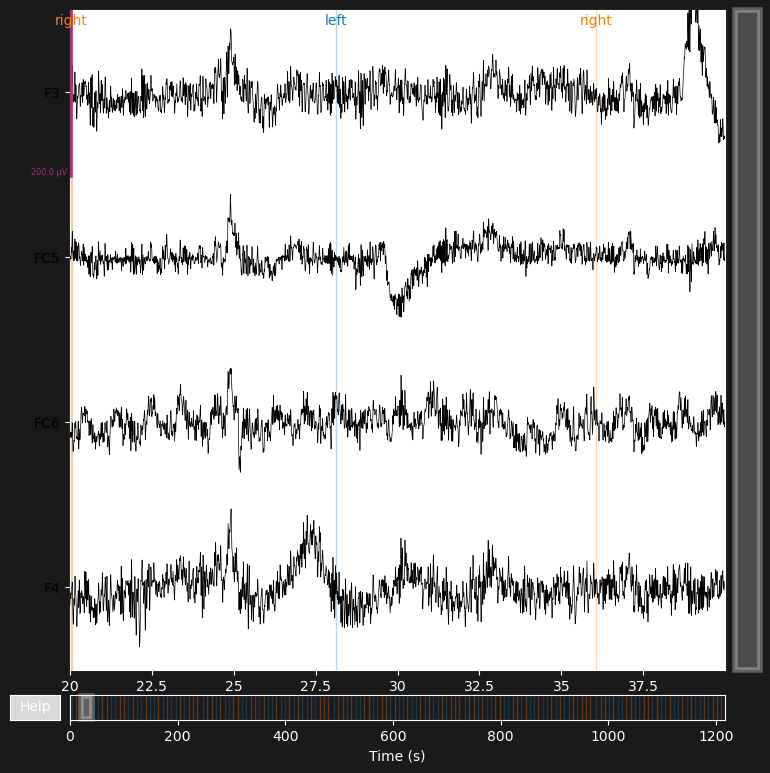

In [4]:
start_sec = 20
end_sec = 40

# Use a wider browser so the channel labels remain visible on the left.
mne.viz.set_browser_backend("matplotlib")
plot_channels = [c for c in ["FC5", "FC6", "F3", "F4"] if c in ch_names_raw]

# Keep every trial in the same class the same color.
annotation_colors = {
    description: (
        "tab:blue" if description == "left"
        else "tab:orange" if description == "right"
        else "tab:gray"
    )
    for description in raw.annotations.description
    if description in {"left", "right"}
}

fig = raw.plot(
    start=start_sec,
    duration=end_sec - start_sec,
    picks=plot_channels,
    n_channels=len(plot_channels),
    scalings=dict(eeg=100e-6),
    annotation_colors=annotation_colors,
)
plt.show()

### Channel Locations (Montage)

So far MNE only knows channel *names*, not where they sit on the scalp. A **montage**
attaches 3-D sensor coordinates to each name, which unlocks topographic (scalp-map)
plotting. All 14 EPOC X channel names are standard 10-20 labels, so MNE's built-in
`standard_1020` montage covers them directly — no manual coordinates needed.

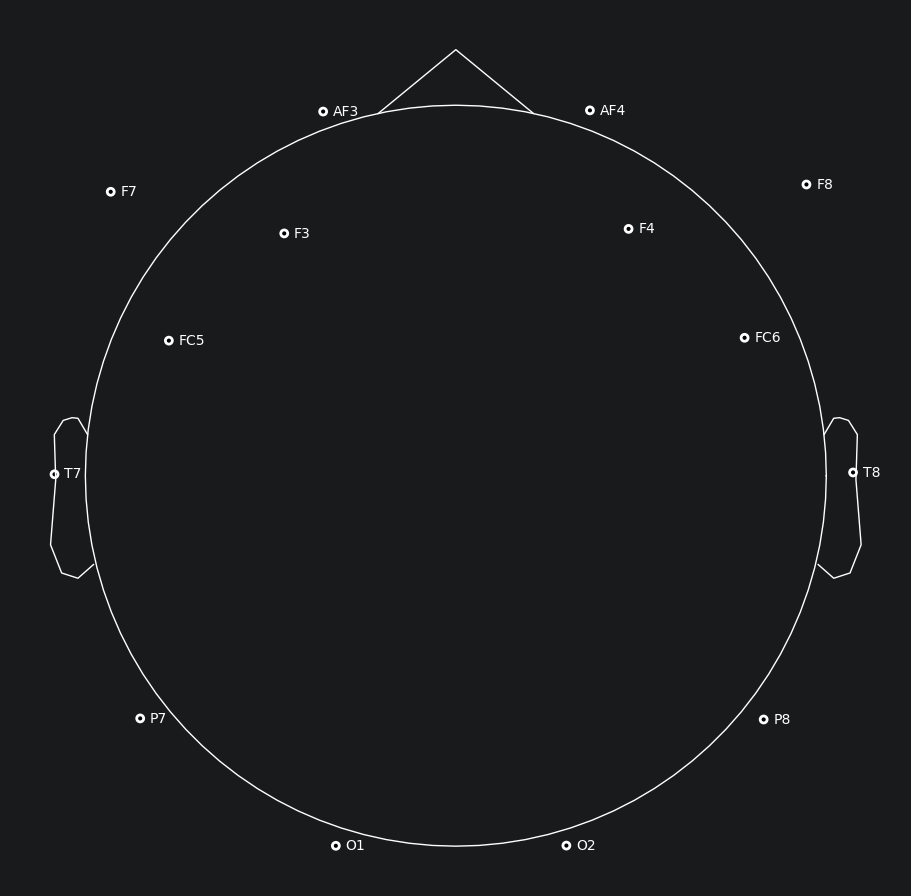

In [5]:
raw.set_montage("standard_1020")
raw.plot_sensors(show_names=True, sphere="auto")
plt.show()

### Power Spectral Density (PSD)

The time-domain plot tells us little about *which* frequencies dominate. `compute_psd()`
runs Welch's method per channel and `.plot()` overlays them. Expect a strong low-frequency
slope (1/f-like) and — since we haven't notch-filtered yet — a spike at **50 Hz** (Tokyo mains
frequency) and its harmonic near 100 Hz. (Here we cannot see a spike at 50 Hz since Emotive automatically applies notch filter before saving EEG data)

/opt/anaconda3/envs/MotorImageryDemo/lib/python3.10/site-packages/mne/viz/utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


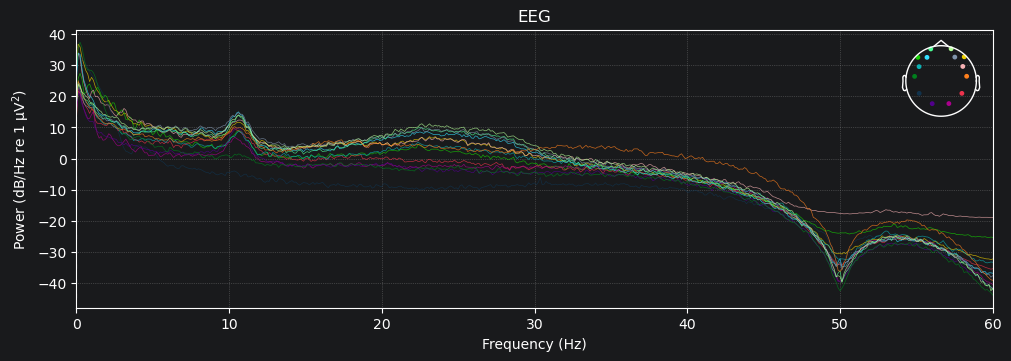

In [6]:
spectrum = raw.compute_psd(fmax=60)
spectrum.plot(average=False, amplitude=False)
plt.show()

## 2. Preprocess with MNE (Notch → Bandpass → CAR) and Epoch

Section 1 concatenated all sessions into one continuous `raw`. We preprocess that
concatenated Raw directly. MNE inserts `BAD boundary` annotations between sessions, and
`reject_by_annotation=True` excludes any epoch that would cross a session boundary.

We apply, in order:
1. **`raw.notch_filter()`** — remove the 50 Hz mains-power noise
2. **`raw.filter()`** — retain the 1–40 Hz EEG frequency range
3. **`raw.set_eeg_reference("average")`** — Common Average Reference (CAR)
4. **`mne.events_from_annotations()` + `mne.Epochs`** — cut out each 4-second MI trial

### 2-1. Remove Noise

In [7]:
# === Preprocessing controls ===
# NOTCH_HZ: remove electrical mains noise at this frequency.
# Use 50.0 in Japan/Europe, 60.0 in North America, or None to disable it.
NOTCH_HZ = 50.0

# BANDPASS_HZ = (low, high): retain EEG frequencies between low and high Hz.
# The default 1–40 Hz range removes slow drifts and attenuates high-frequency noise.
# Examples: (8.0, 30.0) for mu + beta, or (8.0, 13.0) for mu only.
BANDPASS_HZ = (1.0, 40.0)

# APPLY_CAR: True applies Common Average Reference across all EEG channels.
# Set it to False to keep the original channel references.
APPLY_CAR = True

In [8]:
eeg = raw.copy()
# remove line noise
if NOTCH_HZ is not None:
    eeg.notch_filter(freqs=NOTCH_HZ, picks="eeg")
# bandpass filter EEG
eeg.filter(l_freq=BANDPASS_HZ[0], h_freq=BANDPASS_HZ[1], picks="eeg")
# apply common average reference
if APPLY_CAR:
    eeg.set_eeg_reference("average")

Let's check the effect of filtering and CAR on the raw signal with PSD.

/opt/anaconda3/envs/MotorImageryDemo/lib/python3.10/site-packages/mne/viz/utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


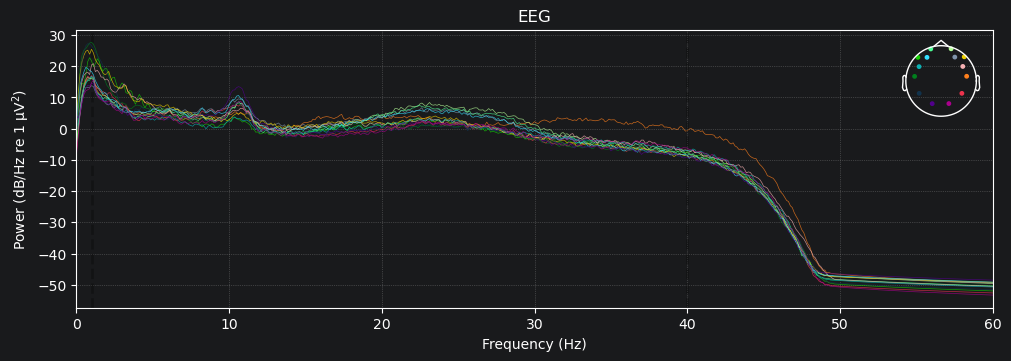

In [9]:
# Power Spectral Density (PSD)
spectrum = eeg.compute_psd(fmax=60)
spectrum.plot(average=False, amplitude=False)
plt.show()

### 2-2. Epoch (cut out trials)

#### Extract and inspect events

- Convert the trial annotations into Left and Right event IDs, then plot their timing across the recording.

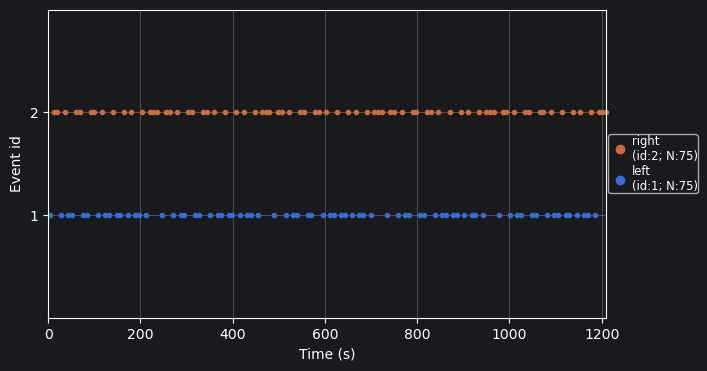

In [10]:
event_dict = {"left": 1, "right": 2}
events, _ = mne.events_from_annotations(eeg, event_id=event_dict)

# Plot the timing and class of all detected trials.
mne.viz.plot_events(
    events,
    sfreq=eeg.info["sfreq"],
    first_samp=eeg.first_samp,
    event_id=event_dict,
)
plt.show()

#### Create epochs

- Extract each trial from **−4 to +4 seconds** relative to MI onset: rest from −4 to −1 s,
  cue from −1 to 0 s, and MI from 0 to +4 s.

In [11]:
epochs = mne.Epochs(
    eeg,
    events,
    event_id=event_dict,
    tmin=-4.0,
    tmax=4.0,
    baseline=None,
    picks="eeg",
    preload=True,
    reject_by_annotation=True,
)

epochs

<Epochs | 150 events (all good), -4 – 4 s (baseline off), ~32.9 MiB, data loaded,
 'left': 75
 'right': 75>

## 3. Inspect Preprocessed Signals and Reject Bad Trials

The recording has 14 EPOC X channels. The figure below maps the headset channel names to
the brain regions underneath.

| EPOC X channel locations | Motor cortex location |
|---|---|
| ![EPOC X channel placement](assets/epoc_channel_locations.png) | ![Motor cortex region](assets/motor_cortex_regions.png) |

_Source: [channel locations](https://www.researchgate.net/figure/Emotiv-EPOC-headset-14-channel-placement-with-two-reference-channels_fig2_309427804) · [motor cortex](https://www.researchgate.net/figure/Primary-brain-regions-Motor-cortex-is-the-region-in-charge-of-planning-control-and_fig2_331905251)._

Inspect every channel in each trial and record trials containing large artifacts or unstable signals.

### Inspect one trial

Set `trial` to an epoch index (starting from 0). Set `channels` to a list of channel names to limit the display, or `None` to display all EEG channels. The red vertical line marks the motor-imagery onset at 0 s.

Trial index: 4


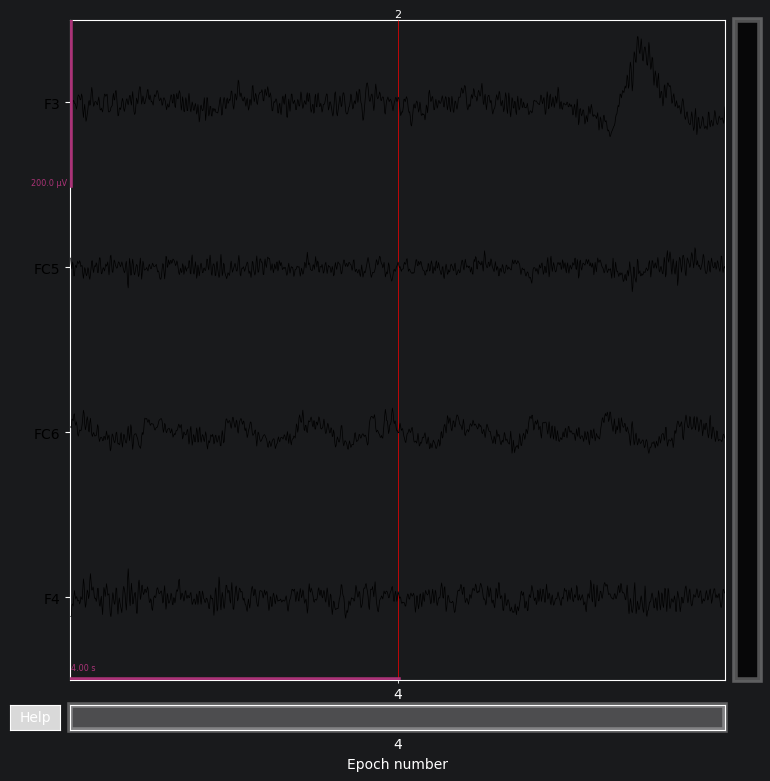

In [12]:
trial = 4
# channels = None  # e.g. ["FC5", "FC6", "F3", "F4"]
channels = ["FC5", "FC6", "F3", "F4"]

selected_channels = epochs.ch_names if channels is None else channels
print(f"Trial index: {trial}")
epochs[trial].plot(
    n_epochs=1,
    picks=selected_channels,
    n_channels=len(selected_channels),
    scalings={"eeg": 100e-6},
    events=True,
    event_color="red",
)
plt.show()

### Mark bad trials

A few high-amplitude trials (movement / blink artifacts) carry so much power that they
dominate the trial-averaged power in Section 4 and bury the ERD/ERS. We flag them
**automatically**: any trial whose overall variance exceeds `THRESHOLD_K` times the median
trial is marked bad. Add any extra indices you spot by eye to `bad_trial_list`.

In [13]:
# Auto-detect artifact trials: those whose variance is far above the typical trial.
THRESHOLD_K = 2  # lower = stricter (rejects more trials)

trial_power = epochs.get_data().var(axis=(1, 2))  # one power value per trial
auto_bad = np.where(trial_power > np.median(trial_power) * THRESHOLD_K)[0]

# Add any extra trials you flagged by eye, e.g. extra_bad = [3, 18]
extra_bad = []
bad_trial_list = sorted(set(auto_bad.tolist()) | set(extra_bad))
print(f"Bad trials: {bad_trial_list}")

Bad trials: [6, 10, 11, 12, 20, 27, 37, 52, 53, 59, 73, 82, 83, 95, 126, 133]


### Remove bad trials

Create a cleaned copy after removing the selected trials.

In [14]:
epochs_clean = epochs.copy()
epochs_clean.drop(bad_trial_list, reason="USER")

print(f"Before: {len(epochs)} trials")
print(f"After : {len(epochs_clean)} trials")

Before: 150 trials
After : 134 trials


## 4. Decoding with ML (CSP + LDA)
| Metric | What it measures | Chance |
|---|---|---|
| **Accuracy** | fraction of trials predicted correctly | 0.50 |
| **Balanced Accuracy** | mean of per-class recall — unaffected by class imbalance | 0.50 |
| **Cohen's κ** | agreement corrected for chance (1 = perfect, 0 = chance) | 0.00 |

### 4-1. CSP (Common Spatial Patterns)

CSP learns a spatial filter — a weighted mix of channels — that **maximizes variance for one
class and minimizes it for the other**. Since band-passed variance equals band power, CSP
builds "composite channels" with the largest left–right power difference. See MNE's
[`CSP` reference](https://mne.tools/stable/generated/mne.decoding.CSP.html) for the full API.

We fit CSP on the MI window only (0–4 s), excluding both rest (−4–−1 s) and cue
(−1–0 s), and draw its spatial patterns on a scalp map (stronger red/blue = higher electrode contribution).

**Note:** this visualization CSP uses all data. In cross-validation (Section 6), CSP is re-fit per fold on training data only, to avoid leakage.

ML preprocessing: 8-30 Hz, CAR
Common bad trials removed: 16; retained: 134


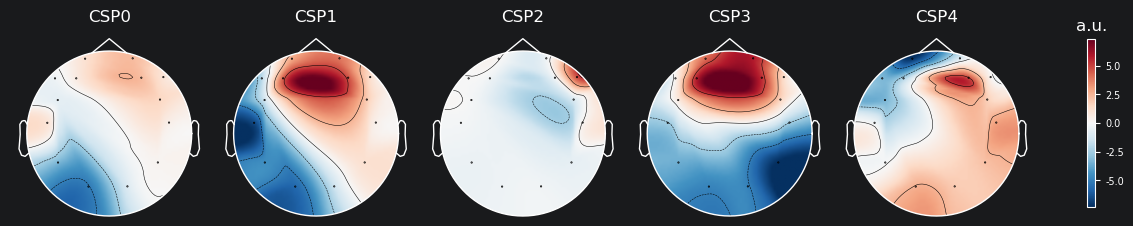

In [15]:
# === ML-specific preprocessing: 8-30 Hz -> CAR -> epoch -> common bad trials ===
ML_BANDPASS_HZ = (8.0, 30.0)
decoding_eeg = raw.copy()
if NOTCH_HZ is not None:
    decoding_eeg.notch_filter(freqs=NOTCH_HZ, picks="eeg")
decoding_eeg.filter(*ML_BANDPASS_HZ, picks="eeg")
decoding_eeg.set_eeg_reference("average", projection=False)

decoding_epochs = mne.Epochs(
    decoding_eeg, events, event_id=event_dict, tmin=-4.0, tmax=4.0,
    baseline=None, picks="eeg", preload=True, reject_by_annotation=True,
)
assert np.array_equal(decoding_epochs.events, epochs.events)
decoding_epochs.drop(bad_trial_list, reason="COMMON_BAD_TRIAL")
assert np.array_equal(decoding_epochs.events, epochs_clean.events)
epochs_mi = decoding_epochs.copy().crop(tmin=0.0, tmax=4.0)

print(f"ML preprocessing: {ML_BANDPASS_HZ[0]:g}-{ML_BANDPASS_HZ[1]:g} Hz, CAR")
print(f"Common bad trials removed: {len(bad_trial_list)}; retained: {len(epochs_mi)}")

# CSP looks for spatial filters that maximize variance (= band power) for one
# class while minimizing it for the other, so it should only see the task window —
# fit it on 0-4 s (MI) and leave out rest (-4 to -1 s) and cue (-1 to 0 s).
X = epochs_mi.get_data(picks="eeg")   # (n_trials, n_channels, n_samples)
y = epochs_mi.events[:, -1] - 1       # mne event ids 1/2 (left/right) -> 0/1

# CAR makes every channel sum to zero, so the spatial covariance is
# rank-deficient (true rank = n_channels - 1). Passing this rank to CSP keeps
# its top component from collapsing onto the empty null direction
# (log-variance ~ -64), which would otherwise make the patterns/features unreadable.
CSP_RANK = {"eeg": X.shape[1] - 1}

csp_vis = CSP(n_components=5, reg="ledoit_wolf", log=True, norm_trace=False, rank=CSP_RANK)
csp_vis.fit(X, y)

# Spatial patterns show each component's contribution per electrode.
csp_vis.plot_patterns(epochs_mi.info, components=range(5), ch_type="eeg", units="a.u.", size=1.5)
plt.show()

#### Before and after CSP filtering

Each point is one EEG time sample in the 0–4 s MI window, colored by trial class.
The reference lecture uses C3 and C4; this 14-channel recording does not contain them,
so the left panel uses the nearest available left–right pair, FC5 and FC6. The right panel
shows the same samples after projection onto two opposing CSP filters, selected to maximize
the variance contrast in opposite directions for the two classes.

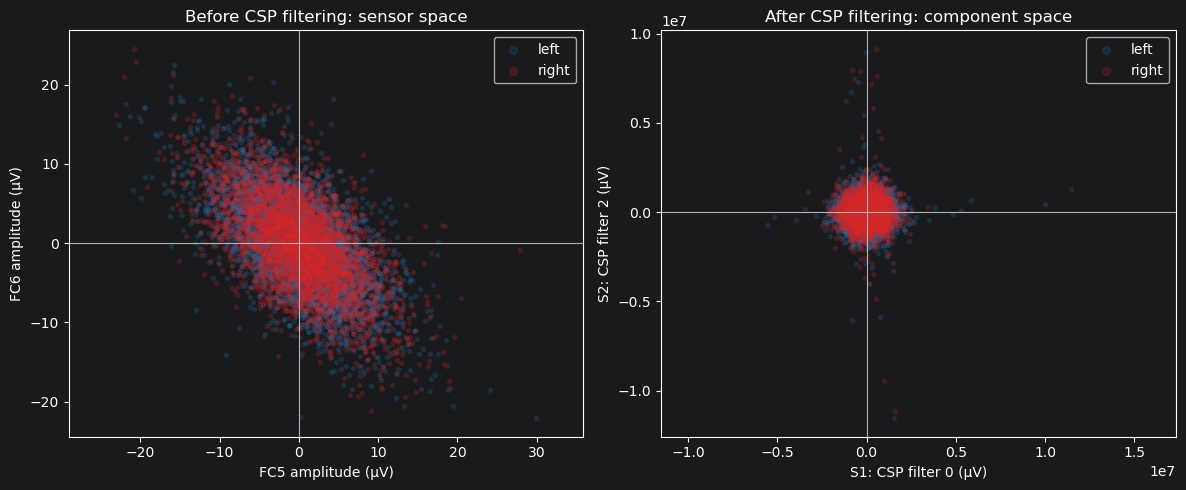

In [16]:
# Compare instantaneous amplitudes before and after CSP, as in the reference lecture.
# Plot a reproducible subset because all trials x all time samples would obscure the distributions.
sensor_pair = ("FC5", "FC6")
missing = [ch for ch in sensor_pair if ch not in epochs_mi.ch_names]
if missing:
    raise ValueError(f"Required channels not found: {missing}")
sensor_idx = [epochs_mi.ch_names.index(ch) for ch in sensor_pair]

# Project the continuous trial signals through every learned CSP spatial filter.
X_csp_signal = np.einsum("kc,nct->nkt", csp_vis.filters_, X)
# Select the opposing filters: one maximizes class-0/class-1 variance and the other the reverse.
class_var = np.array([[np.var(X_csp_signal[y == label, k, :])
                       for k in range(X_csp_signal.shape[1])]
                      for label in (0, 1)])
variance_contrast = np.log(class_var[0] / class_var[1])
csp_pair = (int(np.argmax(variance_contrast)), int(np.argmin(variance_contrast)))
rng = np.random.default_rng(0)
max_points_per_class = 5000

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for label, color in [(0, "tab:blue"), (1, "tab:red")]:
    before = X[y == label][:, sensor_idx, :].transpose(0, 2, 1).reshape(-1, 2) * 1e6
    after = X_csp_signal[y == label][:, csp_pair, :].transpose(0, 2, 1).reshape(-1, 2) * 1e6
    sample_idx = rng.choice(len(before), min(len(before), max_points_per_class), replace=False)
    for ax, points in zip(axes, (before[sample_idx], after[sample_idx])):
        ax.scatter(points[:, 0], points[:, 1], s=8, alpha=0.18, color=color,
                   label=U.LABEL_NAMES[label], rasterized=True)

axes[0].set(xlabel=f"{sensor_pair[0]} amplitude (µV)",
            ylabel=f"{sensor_pair[1]} amplitude (µV)",
            title="Before CSP filtering: sensor space")
axes[1].set(xlabel=f"S1: CSP filter {csp_pair[0]} (µV)",
            ylabel=f"S2: CSP filter {csp_pair[1]} (µV)",
            title="After CSP filtering: component space")
for ax in axes:
    ax.axhline(0, color="0.7", linewidth=0.8)
    ax.axvline(0, color="0.7", linewidth=0.8)
    ax.set_aspect("equal", adjustable="datalim")
    ax.legend(markerscale=2)
plt.tight_layout()
plt.show()

### 4-2. CSP Feature Space

For each trial, we summarize the same two opposing CSP signals selected in Section 4-1
by their log-variance (band power). Each point now represents one complete MI trial.

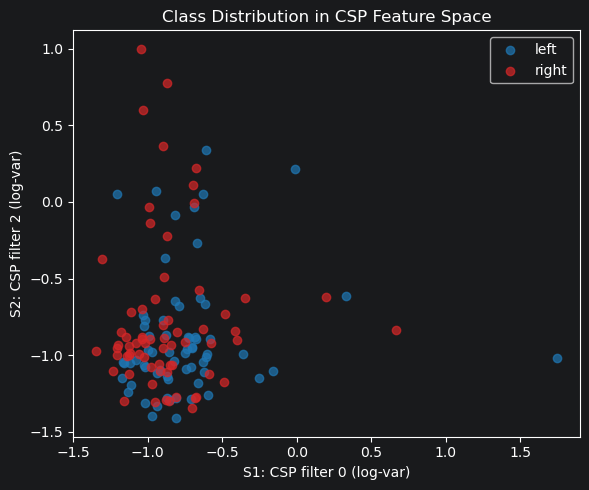

In [17]:
# Trial-level log-power features from the same opposing CSP signals shown in Section 4-1.
feat_pair = np.log(np.var(X_csp_signal[:, csp_pair, :], axis=-1))

fig, ax = plt.subplots(figsize=(6, 5))
for label, color in [(0, "tab:blue"), (1, "tab:red")]:
    mask = y == label
    ax.scatter(feat_pair[mask, 0], feat_pair[mask, 1], c=color,
               label=U.LABEL_NAMES[label], alpha=0.7)
ax.set(xlabel=f"S1: CSP filter {csp_pair[0]} (log-var)",
       ylabel=f"S2: CSP filter {csp_pair[1]} (log-var)",
       title="Class Distribution in CSP Feature Space")
ax.legend()
plt.tight_layout()
plt.show()

## 4-3. CSP + LDA

The classical baseline: **CSP** builds spatial filters that maximize the left–right band-power
difference, and a **Linear Discriminant Analysis (LDA)** classifier draws a straight
boundary in that feature space. Both live in one scikit-learn `Pipeline`, so CSP is re-fit on the
training trials **inside every fold** — no test-set leakage.

In [22]:
# === Shared evaluation setup ===
DECODE_CHANNELS = None  # None: all EEG channels; or e.g. ["FC5", "FC6", "F3", "F4"]
decode_picks = "eeg" if DECODE_CHANNELS is None else DECODE_CHANNELS

# Section 4-1 created the ML-specific 0-4 s motor-imagery epochs and labels.
X = epochs_mi.get_data(picks=decode_picks)
y = epochs_mi.events[:, -1] - 1
trial_ids = np.arange(len(y))

n_selected = X.shape[1]
n_eeg_total = len(mne.pick_types(epochs_mi.info, eeg=True))
N_CSP = min(4, n_selected)
CSP_RANK = {"eeg": n_selected - 1} if n_selected == n_eeg_total else None

# Both notebooks use this exact splitter. fold_id makes the assignment easy to compare.
CV_SEED = 0
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=CV_SEED)
folds = list(cv.split(X, y))
fold_id = np.empty(len(y), dtype=int)
for k, (_, test_idx) in enumerate(folds):
    fold_id[test_idx] = k


def evaluate(name, y_true, y_pred):
    scores = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "cohen_kappa": cohen_kappa_score(y_true, y_pred),
    }
    print(f"{name:10s} | acc={scores['accuracy']:.3f}"
          f" | balanced acc={scores['balanced_accuracy']:.3f}"
          f" | Cohen's κ={scores['cohen_kappa']:+.3f}")
    return scores


def misclassified(y_true, y_pred):
    wrong = np.flatnonzero(y_true != y_pred)
    return pd.DataFrame({
        "trial_id": trial_ids[wrong],
        "fold": fold_id[wrong],
        "true": [U.LABEL_NAMES[c] for c in y_true[wrong]],
        "predicted": [U.LABEL_NAMES[c] for c in y_pred[wrong]],
    })


print(f"Input: {X.shape} | labels: {np.bincount(y).tolist()}")
print(f"Fold test sizes: {np.bincount(fold_id).tolist()}")
print("Channels:", epochs_mi.copy().pick(decode_picks).ch_names)

Input: (134, 14, 1025) | labels: [67, 67]
Fold test sizes: [27, 27, 27, 27, 26]
Channels: ['AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1', 'O2', 'P8', 'T8', 'FC6', 'F4', 'F8', 'AF4']


#### 4-3-1 Evaluate the model

In [19]:
csp_lda = Pipeline([
    ("csp", CSP(n_components=N_CSP, reg="ledoit_wolf", log=True, rank=CSP_RANK)),
    ("clf", LDA()),
])

# CSP is fitted only on each fold's training trials because it is inside the pipeline.
y_pred_csp = cross_val_predict(csp_lda, X, y, cv=folds)
scores_csp = evaluate("CSP + LDA", y, y_pred_csp)

CSP + LDA  | acc=0.560 | balanced acc=0.560 | Cohen's κ=+0.119


#### 4-3-2 Analysis

For this error analysis, the two displayed axes are selected only from the `N_CSP`
features actually available to the classifier: the most left-dominant and the most
right-dominant component by mean log-variance contrast.

CSP + LDA misclassified 59 / 134 trials


,trial_id,fold,true,predicted
0,0,1,left,right
1,3,4,left,right
2,5,2,left,right
3,11,3,left,right
4,12,1,left,right
5,15,3,left,right
6,16,1,left,right
7,17,3,right,left
8,19,3,left,right
9,21,3,left,right


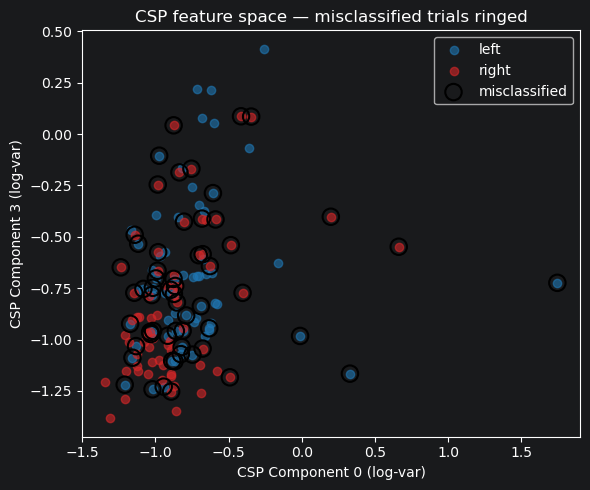

In [23]:
# Misclassified trial table (held-out predictions).
mis_csp = misclassified(y, y_pred_csp)
print(f"CSP + LDA misclassified {len(mis_csp)} / {len(y)} trials")
display(mis_csp)

# Fit on all trials only for this visualization. Rings mark CV misclassifications.
csp_view = CSP(n_components=N_CSP, reg="ledoit_wolf", log=True, rank=CSP_RANK)
features = csp_view.fit_transform(X, y)
analysis_contrast = features[y == 0].mean(axis=0) - features[y == 1].mean(axis=0)
analysis_csp_pair = (int(np.argmax(analysis_contrast)), int(np.argmin(analysis_contrast)))
wrong = y_pred_csp != y

fig, ax = plt.subplots(figsize=(6, 5))
for label, color in [(0, "tab:blue"), (1, "tab:red")]:
    mask = y == label
    ax.scatter(features[mask, analysis_csp_pair[0]],
               features[mask, analysis_csp_pair[1]], c=color, alpha=0.6,
               label=U.LABEL_NAMES[label])
ax.scatter(features[wrong, analysis_csp_pair[0]],
           features[wrong, analysis_csp_pair[1]], s=140, facecolors="none",
           edgecolors="k", linewidths=1.5, label="misclassified")
ax.set(xlabel=f"CSP Component {analysis_csp_pair[0]} (log-var; left-dominant)",
       ylabel=f"CSP Component {analysis_csp_pair[1]} (log-var; right-dominant)",
       title="CSP feature space — misclassified trials ringed")
ax.legend()
plt.tight_layout()
plt.show()